<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/cnn_baseline_models/01_UNet%2BResNet34.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains the complete training log and evaluation output for UNet+ResNet34 on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.



In [ ]:
# Install required packages
!pip install -q webdataset segmentation-models-pytorch albumentations

# Now import everything
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import numpy as np
import torch
import torch.nn as nn
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import random
import warnings
warnings.filterwarnings("ignore")

print("✅ All imports loaded successfully!")
print("🎉 Ready for training!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ All imports loaded successfully!
🎉 Ready for training!


In [ ]:
# Your exact dataset paths
drive_dataset_path = "/content/drive/MyDrive/YOUR_DATASET_PATH"
colab_dataset_path = "/content/drive/MyDrive/YOUR_DATASET_PATH"

# Copy to local (faster)
os.makedirs(os.path.dirname(colab_dataset_path), exist_ok=True)
print("📥 Copying dataset...")
shutil.copy(drive_dataset_path, colab_dataset_path)
print(f"✅ Dataset ready: {os.path.getsize(colab_dataset_path)/1024**3:.2f} GB")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Device: {device}")
wds_path = colab_dataset_path


In [ ]:
MODEL_NAME = "UNet_ResNet34"
final_results_path = "/content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results"
model_results_path = os.path.join(final_results_path, MODEL_NAME)

os.makedirs(model_results_path, exist_ok=True)
print(f"📁 Results folder: {model_results_path}")
print("✅ Ready to save all results here!")


📁 Results folder: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/UNet_ResNet34
✅ Ready to save all results here!


In [ ]:
CONFIG = {
    "model_name": MODEL_NAME,
    "encoder_name": "resnet34",
    "num_epochs": 50,
    "batch_size": 16,
    "learning_rate": 1e-4,
    "num_workers": 0,
    "total_patches": 5000
}

CONFIG["train_size"] = int(CONFIG["total_patches"] * 0.7)
CONFIG["val_size"] = int(CONFIG["total_patches"] * 0.2)
CONFIG["test_size"] = CONFIG["total_patches"] - CONFIG["train_size"] - CONFIG["val_size"]

train_batches = CONFIG["train_size"] // CONFIG["batch_size"]
val_batches = CONFIG["val_size"] // CONFIG["batch_size"]

print(f"📊 Split: {CONFIG['train_size']}/{CONFIG['val_size']}/{CONFIG['test_size']}")
print(f"📦 Batches: Train={train_batches}, Val={val_batches}")


📊 Split: 3500/1000/500
📦 Batches: Train=218, Val=62


In [ ]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

def preprocess_sample(sample, transform):
    img = np.array(sample["image.png"].convert("RGB"))
    msk = np.array(sample["mask.png"].convert("L")) / 255.0
    t = transform(image=img, mask=msk)
    return t["image"], t["mask"].unsqueeze(0)

print("✅ Augmentations ready!")


✅ Augmentations ready!


In [ ]:
train_dataset = (wds.WebDataset(wds_path)
    .shuffle(1000).decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG["batch_size"]))

val_dataset = (wds.WebDataset(wds_path)
    .decode("pil").to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG["batch_size"]))

train_loader = wds.WebLoader(train_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(train_batches)
val_loader = wds.WebLoader(val_dataset, batch_size=None, num_workers=CONFIG["num_workers"]).with_epoch(val_batches)

print("✅ Data loaders ready!")
print(f"Train batches/epoch: {train_batches}")
print(f"Val batches/epoch: {val_batches}")


✅ Data loaders ready!
Train batches/epoch: 218
Val batches/epoch: 62


In [ ]:
print("🔨 Building U-Net (ResNet34 + ImageNet weights)...")

model = smp.Unet(
    encoder_name=CONFIG["encoder_name"],
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"✅ Model ready!")
print(f"📈 Total parameters: {total_params:,}")
print(f"💾 Model size: {total_params*4/1024**2:.1f} MB")


🔨 Building U-Net (ResNet34 + ImageNet weights)...


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

✅ Model ready!
📈 Total parameters: 24,436,369
💾 Model size: 93.2 MB


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__();
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, pred, target):
        bce = self.bce(pred, target)
        p = torch.sigmoid(pred)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + 1e-6) / (p.sum() + target.sum() + 1e-6)
        return 0.5 * bce + 0.5 * dice

def calc_iou(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    union = pred.sum() + target.sum() - inter
    return (inter + 1e-6) / (union + 1e-6)

def calc_dice(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    inter = (pred * target).sum()
    return (2 * inter + 1e-6) / (pred.sum() + target.sum() + 1e-6)

def calc_precision(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (pred.sum() + 1e-6)

def calc_recall(pred, target, thr=0.5):
    pred = (torch.sigmoid(pred) > thr).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (target.sum() + 1e-6)

criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=5, factor=0.5)

history = {"train_loss":[], "val_loss":[], "train_iou":[], "val_iou":[],
           "train_dice":[], "val_dice":[], "train_precision":[], "val_precision":[],
           "train_recall":[], "val_recall":[], "learning_rate":[]}

best_dice = 0.0
print("✅ Loss/Metrics/Optimizer ready!")


✅ Loss/Metrics/Optimizer ready!


In [ ]:
def train_epoch(model, loader, num_batches):
    model.train()
    losses, ious, dices, precs, recs = [], [], [], [], []
    pbar = tqdm(enumerate(loader), total=num_batches, desc="Train")
    for bi, (imgs, msks) in pbar:
        if bi >= num_batches: break
        imgs, msks = imgs.to(device), msks.to(device)
        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, msks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        losses.append(loss.item())
        ious.append(calc_iou(preds, msks).item())
        dices.append(calc_dice(preds, msks).item())
        precs.append(calc_precision(preds, msks).item())
        recs.append(calc_recall(preds, msks).item())
        pbar.set_postfix(loss=f"{np.mean(losses):.4f}", dice=f"{np.mean(dices):.4f}")
    return {"loss": np.mean(losses), "iou": np.mean(ious), "dice": np.mean(dices),
            "precision": np.mean(precs), "recall": np.mean(recs)}

def val_epoch(model, loader, num_batches):
    model.eval()
    losses, ious, dices, precs, recs = [], [], [], [], []
    with torch.no_grad():
        pbar = tqdm(enumerate(loader), total=num_batches, desc="Val")
        for bi, (imgs, msks) in pbar:
            if bi >= num_batches: break
            imgs, msks = imgs.to(device), msks.to(device)
            preds = model(imgs)
            loss = criterion(preds, msks)
            losses.append(loss.item())
            ious.append(calc_iou(preds, msks).item())
            dices.append(calc_dice(preds, msks).item())
            precs.append(calc_precision(preds, msks).item())
            recs.append(calc_recall(preds, msks).item())
            pbar.set_postfix(loss=f"{np.mean(losses):.4f}", dice=f"{np.mean(dices):.4f}")
    return {"loss": np.mean(losses), "iou": np.mean(ious), "dice": np.mean(dices),
            "precision": np.mean(precs), "recall": np.mean(recs)}

print("✅ Training functions ready!")


✅ Training functions ready!


In [ ]:
print("="*80)
print(f"🚀 START TRAINING: {CONFIG['model_name']}")
print("="*80)

for epoch in range(CONFIG["num_epochs"]):
    print(f"\nEpoch {epoch+1}/{CONFIG['num_epochs']}")

    train_m = train_epoch(model, train_loader, train_batches)
    val_m = val_epoch(model, val_loader, val_batches)

    # Update scheduler & history
    val_loss = val_m["loss"]
    scheduler.step(val_loss)
    lr = optimizer.param_groups[0]["lr"]

    for k in ["loss", "iou", "dice", "precision", "recall"]:
        history[f"train_{k}"].append(train_m[k])
        history[f"val_{k}"].append(val_m[k])
    history["learning_rate"].append(lr)

    print(f"LR: {lr:.2e} | Train Dice: {train_m['dice']:.4f} | Val Dice: {val_m['dice']:.4f}")

    if val_m["dice"] > best_dice:
        best_dice = val_m["dice"]
        torch.save(model.state_dict(), os.path.join(model_results_path, "best_model.pth"))
        print(f"  ⭐ NEW BEST: {best_dice:.4f}")

print(f"\n🎉 TRAINING COMPLETE! Best Dice: {best_dice:.4f}")


In [ ]:
# Save final model & history
torch.save(model.state_dict(), os.path.join(model_results_path, "final_model.pth"))
pd.DataFrame(history).to_csv(os.path.join(model_results_path, "training_history.csv"), index=False)

print("✅ SAVED:")
print(f"   📁 {model_results_path}")
print(f"   ⭐ best_model.pth")
print(f"   📈 final_model.pth")
print(f"   📊 training_history.csv")


✅ SAVED:
   📁 /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/UNet_ResNet34
   ⭐ best_model.pth
   📈 final_model.pth
   📊 training_history.csv


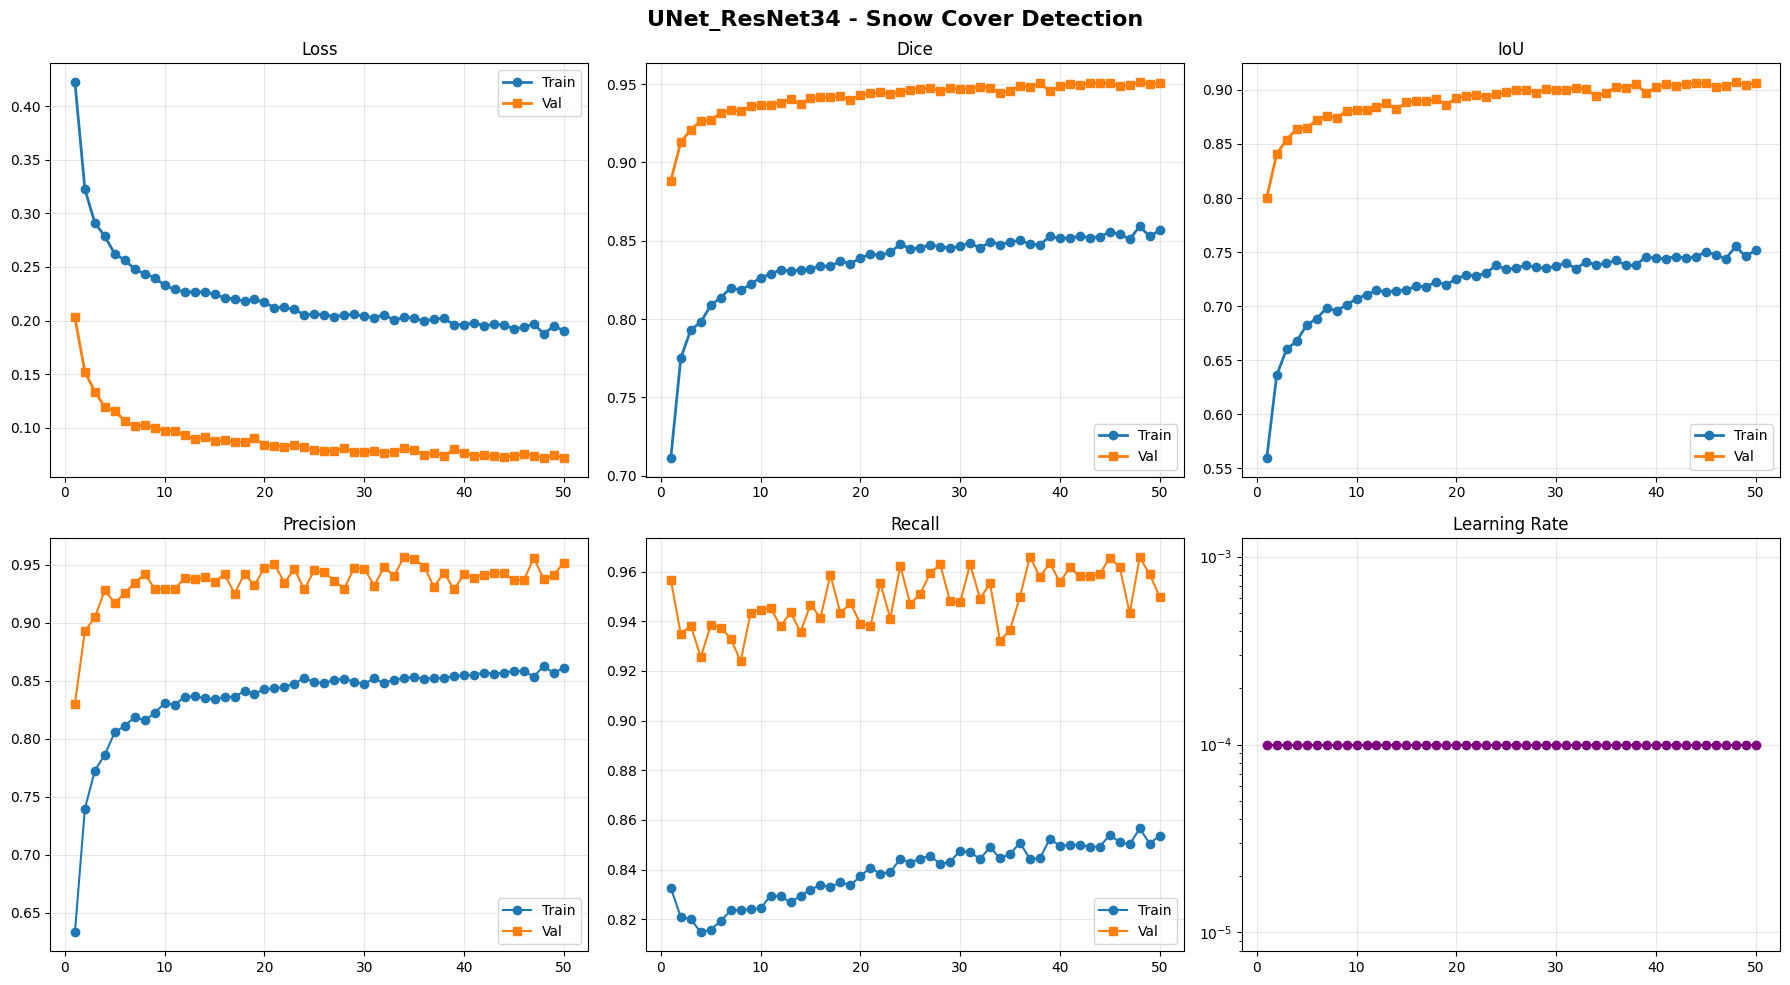

✅ Plot saved: training_curves.png


In [ ]:
epochs = np.arange(1, CONFIG["num_epochs"] + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics = [("train_loss", "val_loss", "Loss"), ("train_dice", "val_dice", "Dice"),
           ("train_iou", "val_iou", "IoU")]
for i, (tr, vl, title) in enumerate(metrics):
    axes[0, i].plot(epochs, history[tr], "o-", label="Train", linewidth=2)
    axes[0, i].plot(epochs, history[vl], "s-", label="Val", linewidth=2)
    axes[0, i].set_title(title); axes[0, i].legend(); axes[0, i].grid(alpha=0.3)

axes[1, 0].plot(epochs, history["train_precision"], "o-", label="Train")
axes[1, 0].plot(epochs, history["val_precision"], "s-", label="Val")
axes[1, 0].set_title("Precision"); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(epochs, history["train_recall"], "o-", label="Train")
axes[1, 1].plot(epochs, history["val_recall"], "s-", label="Val")
axes[1, 1].set_title("Recall"); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

axes[1, 2].plot(epochs, history["learning_rate"], "o-", color="purple")
axes[1, 2].set_title("Learning Rate"); axes[1, 2].set_yscale("log"); axes[1, 2].grid(alpha=0.3)

plt.suptitle(f"{MODEL_NAME} - Snow Cover Detection", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(model_results_path, "training_curves.png"), dpi=300, bbox_inches="tight")
plt.show()

print("✅ Plot saved: training_curves.png")


In [ ]:
print("="*80)
print("🎨 GENERATING TEST PREDICTIONS (WHITE SNOW)")
print("="*80)

# Load BEST model
best_model_path = os.path.join(model_results_path, "best_model.pth")
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()
print(f"✅ Loaded best model: Dice={best_dice:.4f}")

# Raw dataset for test sampling
raw_ds = wds.WebDataset(wds_path).decode("pil").to_tuple("image.png", "mask.png")
all_samples = list(raw_ds)

# Test samples from test split
random.seed(42)
num_samples = 8
test_indices = random.sample(range(CONFIG["train_size"] + CONFIG["val_size"], len(all_samples)), num_samples)

# Generate predictions
sample_images, sample_masks, sample_preds = [], [], []
sample_dice_scores, sample_iou_scores = [], []

with torch.no_grad():
    for idx in test_indices:
        img_pil, mask_pil = all_samples[idx]
        img_np = np.array(img_pil.convert("RGB"))
        mask_np = (np.array(mask_pil.convert("L")) / 255.0).astype(np.float32)

        t = val_transform(image=img_np, mask=mask_np)
        img_t = t["image"].unsqueeze(0).to(device)

        pred = model(img_t)
        pred_prob = torch.sigmoid(pred).squeeze().cpu().numpy()

        dice = calc_dice(torch.from_numpy(pred_prob).unsqueeze(0).unsqueeze(0),
                        torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0)).item()
        iou = calc_iou(torch.from_numpy(pred_prob).unsqueeze(0).unsqueeze(0),
                      torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0)).item()

        sample_images.append(img_np)
        sample_masks.append(mask_np)
        sample_preds.append(pred_prob)
        sample_dice_scores.append(dice)
        sample_iou_scores.append(iou)

print(f"✅ Generated {num_samples} predictions")
print(f"📈 Avg Dice: {np.mean(sample_dice_scores):.4f}")


🎨 GENERATING TEST PREDICTIONS (WHITE SNOW)
✅ Loaded best model: Dice=0.9513
✅ Generated 8 predictions
📈 Avg Dice: 0.3537


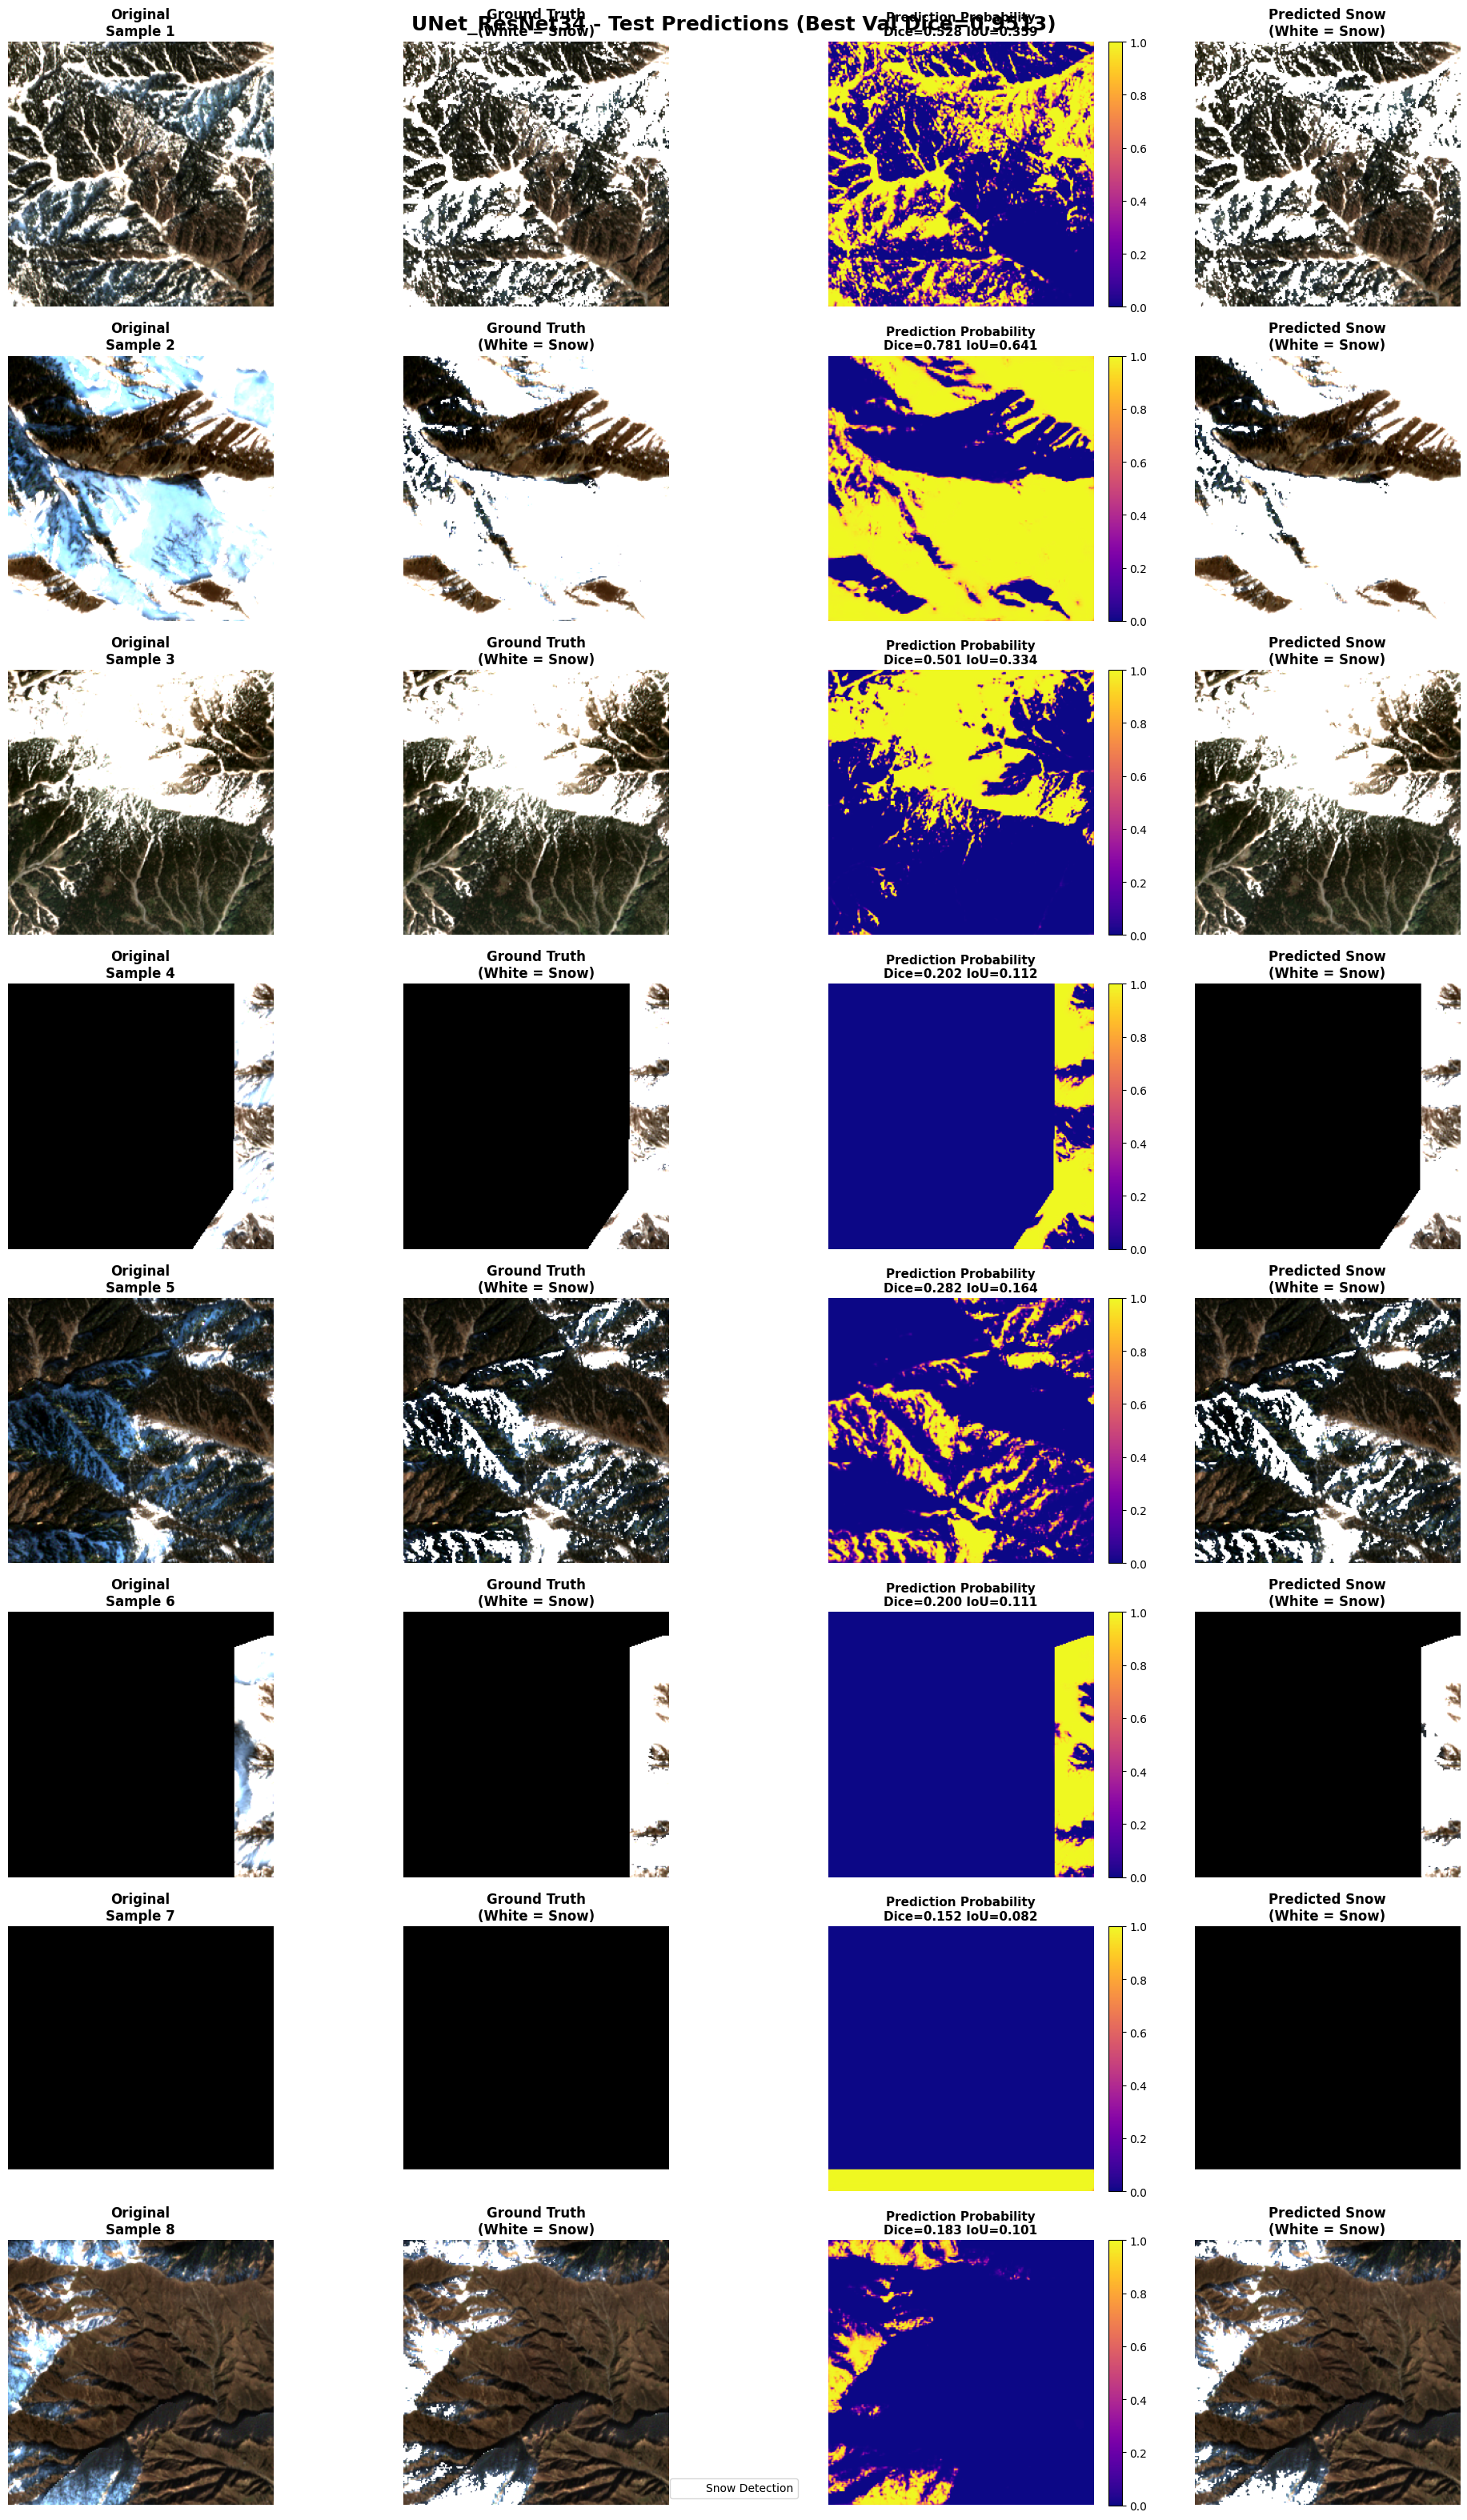

✅ WHITE SNOW visualization saved: /content/drive/My Drive/Swat_Snow_Cover_Project/Final_Results/UNet_ResNet34/test_predictions_WHITE_SNOW.png


In [ ]:
# Create WHITE SNOW visualization
fig, axes = plt.subplots(num_samples, 4, figsize=(20, 4*num_samples))

if num_samples == 1:
    axes = axes.reshape(1, -1)

for i in range(num_samples):
    img, msk, pred, d, j = sample_images[i], sample_masks[i], sample_preds[i], sample_dice_scores[i], sample_iou_scores[i]

    # BINARY PREDICTION (threshold 0.5)
    pred_bin = (pred > 0.5).astype(np.uint8)

    # === WHITE SNOW OVERLAY ===
    overlay = img.astype(np.float32).copy()
    # Add WHITE snow overlay (bright white on top of image)
    overlay[pred_bin == 1] = [255, 255, 255]  # Pure white for snow pixels
    overlay = overlay.astype(np.uint8)

    # === GROUND TRUTH OVERLAY (for comparison) ===
    gt_overlay = img.astype(np.float32).copy()
    gt_overlay[msk > 0.5] = [255, 255, 255]  # White for GT snow
    gt_overlay = gt_overlay.astype(np.uint8)

    # Column 1: Original Image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Original\nSample {i+1}", fontweight="bold", fontsize=12)
    axes[i, 0].axis("off")

    # Column 2: Ground Truth (White Snow Overlay)
    axes[i, 1].imshow(gt_overlay)
    axes[i, 1].set_title("Ground Truth\n(White = Snow)", fontweight="bold", fontsize=12)
    axes[i, 1].axis("off")

    # Column 3: Prediction Probability + Metrics
    im = axes[i, 2].imshow(pred, cmap="plasma", vmin=0, vmax=1)
    axes[i, 2].set_title(f"Prediction Probability\nDice={d:.3f} IoU={j:.3f}",
                        fontweight="bold", fontsize=11)
    axes[i, 2].axis("off")
    plt.colorbar(im, ax=axes[i, 2], fraction=0.046, pad=0.04)

    # Column 4: Predicted Snow Overlay (WHITE SNOW)
    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Predicted Snow\n(White = Snow)", fontweight="bold", fontsize=12)
    axes[i, 3].axis("off")

# Legend
legend_elements = [mpatches.Patch(color='white', label='Snow Detection')]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=1)

plt.suptitle(f"{MODEL_NAME} - Test Predictions (Best Val Dice={best_dice:.4f})",
             fontsize=18, fontweight="bold", y=0.98)
plt.tight_layout()
vis_path = os.path.join(model_results_path, "test_predictions_WHITE_SNOW.png")
plt.savefig(vis_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ WHITE SNOW visualization saved: {vis_path}")


In [ ]:
# Print detailed test stats
print("\n📊 TEST SET SAMPLE STATISTICS")
print("-" * 50)
print(f"{'Sample':<8} {'Dice':<8} {'IoU':<8} {'Precision':<8} {'Recall':<10}")
print("-" * 50)

for i in range(num_samples):
    pred_t = torch.from_numpy(sample_preds[i]).unsqueeze(0).unsqueeze(0)
    mask_t = torch.from_numpy(sample_masks[i]).unsqueeze(0).unsqueeze(0)
    prec = calc_precision(pred_t, mask_t).item()
    rec = calc_recall(pred_t, mask_t).item()

    print(f"{i+1:<8} {sample_dice_scores[i]:<8.4f} {sample_iou_scores[i]:<8.4f} "
          f"{prec:<8.4f} {rec:<10.4f}")

print("\n📈 AVERAGES:")
print(f"{'Avg Dice':<8} {np.mean(sample_dice_scores):.4f}")
print(f"{'Avg IoU':<8} {np.mean(sample_iou_scores):.4f}")

# Save metrics
test_metrics = {
    "sample_dice": sample_dice_scores,
    "sample_iou": sample_iou_scores,
    "avg_dice": np.mean(sample_dice_scores),
    "avg_iou": np.mean(sample_iou_scores),
    "best_val_dice": best_dice
}
pd.DataFrame(test_metrics).to_csv(os.path.join(model_results_path, "test_metrics.csv"), index=False)
print("✅ Test metrics saved: test_metrics.csv")



📊 TEST SET SAMPLE STATISTICS
--------------------------------------------------
Sample   Dice     IoU      Precision Recall    
--------------------------------------------------
1        0.5283   0.3590   0.3590   1.0000    
2        0.7810   0.6407   0.6407   1.0000    
3        0.5013   0.3345   0.3345   1.0000    
4        0.2022   0.1125   0.1125   1.0000    
5        0.2815   0.1638   0.1638   1.0000    
6        0.2002   0.1112   0.1112   1.0000    
7        0.1516   0.0820   0.0820   1.0000    
8        0.1832   0.1008   0.1008   1.0000    

📈 AVERAGES:
Avg Dice 0.3537
Avg IoU  0.2381
✅ Test metrics saved: test_metrics.csv
